In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_auc_score, log_loss
from sklearn.metrics import roc_curve
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
import xgboost as xgb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')


from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

import networkx as nx
from nltk.tokenize import word_tokenize
import re
import csv
import os
import nltk

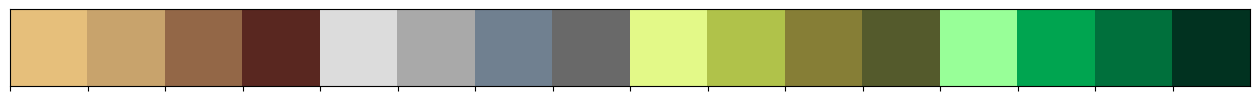

In [ ]:
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",None)

colors = [
    "#e6bf7b", "#c8a36c", "#936747", "#592720", "#dcdcdc", "#a9a9a9",
    "#708090", "#696969", "#e3f988", "#b0c24a", "#867e36", "#545a2c",
    "#98ff98", "#00a550", "#00703c", "#013220"
]
sns.palplot(sns.color_palette(colors))

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving SCADA_Network_CyberAttacks_Vulnerability_Data.csv to SCADA_Network_CyberAttacks_Vulnerability_Data.csv


In [ ]:
data = pd.read_csv("SCADA_Network_CyberAttacks_Vulnerability_Data.csv")

In [ ]:
print(data.shape)

(501, 16)


In [ ]:
data.head(60)

,Scenario,Vulnerable_event_type,Cyber_attack,Intrusion,Network_device,Intelligent_electronic_device(IED),Circuit_breaker_of_IED,Power_transmission_line_of_Circuit_breakers,Single-line-to-ground(SLG)_fault_of_power_line,Tripping_command_issue_of_power_line,Command_injection_against_IED_Relay,IED_Relay_disabled_issue,IED_Relay_fault_issue,Open_breaker_issue_by_command_injection,Downtime_issue,Power_line_maintenance_issue
0,1,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
1,2,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
2,3,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
3,4,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
4,5,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
5,6,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
6,7,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
7,8,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
8,9,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
9,10,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance


# **SCADA-Digital-Twin for Cyber-attacks**

In [ ]:
# Selecting 41 senarios for digital-twin simulation
subset = data.iloc[0:42]
print(subset.shape)
subset.head(10)

(42, 16)


,Scenario,Vulnerable_event_type,Cyber_attack,Intrusion,Network_device,Intelligent_electronic_device(IED),Circuit_breaker_of_IED,Power_transmission_line_of_Circuit_breakers,Single-line-to-ground(SLG)_fault_of_power_line,Tripping_command_issue_of_power_line,Command_injection_against_IED_Relay,IED_Relay_disabled_issue,IED_Relay_fault_issue,Open_breaker_issue_by_command_injection,Downtime_issue,Power_line_maintenance_issue
0,1,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
1,2,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
2,3,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
3,4,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
4,5,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
5,6,Non_attack_vulnerability,Non_attack,No_network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,No tripping command Issue,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
6,7,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
7,8,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
8,9,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_1-&-2,Circuit_breaker_1-&-2,Line_1,SLG-fault on line L1,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance
9,10,Cyber_attack,FDIA,Network_intrusion,Substation_Network_Switch_1,IED_Relay_3-&-4,Circuit_breaker_3-&-4,Line_2,SLG-fault on line L2,Tripping command problem,No Command against IED_Relay,No IED_relay disable issue,No IED_relay fault issue,No open breaker issue,No downtime issue,No_power_line_maintenance


In [ ]:
# Keep only the specific row by using iloc
#specific_triple_kg = triple_kg.iloc[6:9]
specific_triple_kg = subset[subset['Cyber_attack'].isin(['FDIA', 'DoS', 'SRA', 'RTCI'])]

In [ ]:
def generate_kg(source, target, relations, width, height):
    # generate the knowledge graph using networkx library
    G = nx.DiGraph(directed=True)
    for i in range(len(relations)):
        G.add_weighted_edges_from([(source[i], target[i], i)])
        #print(G.nodes)
        #print(len(G.edges))
    print("\n Knowledge Graph generated")
    size = 6
    plt.figure(figsize=(width,height))
    edge_labels= dict([((u,v), relations[d['weight']]) for u,v, d in G.edges(data=True)])
    pos=nx.spring_layout(G,k=10)
    nx.draw(G, with_labels=True, node_color='lightblue', node_size=2000, edge_color='r', edge_cmap=plt.cm.Blues, pos=pos, font_size=7)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)
    plt.show()



 Knowledge Graph generated


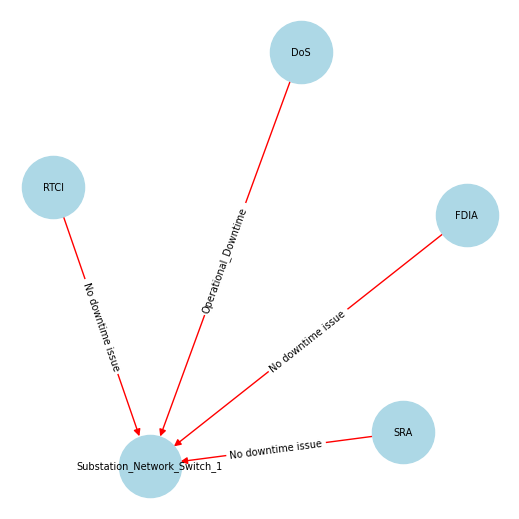

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Network_device'].tolist()
relations = specific_triple_kg['Downtime_issue'].tolist()
generate_kg(source, target, relations, 5, 5)


 Knowledge Graph generated


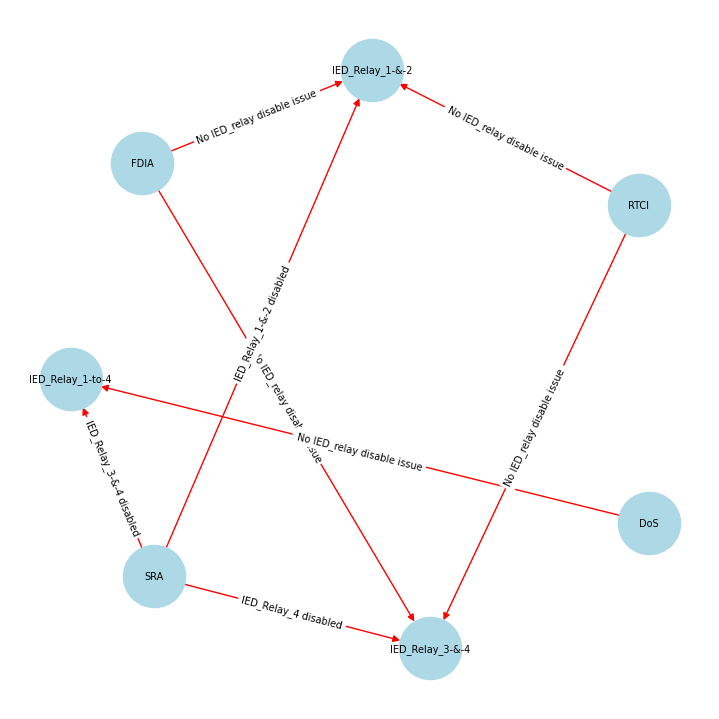

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Intelligent_electronic_device(IED)'].tolist()
relations = specific_triple_kg['IED_Relay_disabled_issue'].tolist()
generate_kg(source, target, relations, 7, 7)


 Knowledge Graph generated


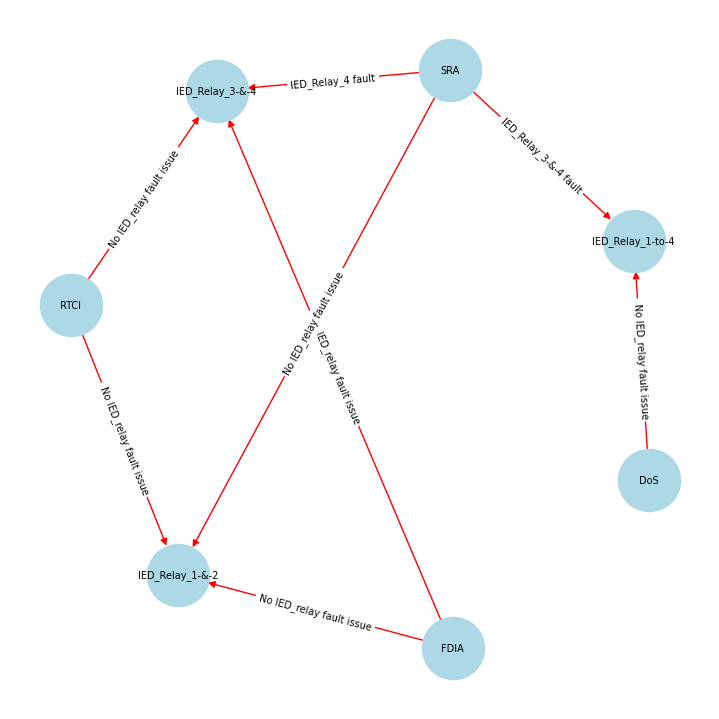

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Intelligent_electronic_device(IED)'].tolist()
relations = specific_triple_kg['IED_Relay_fault_issue'].tolist()
generate_kg(source, target, relations, 7, 7)


 Knowledge Graph generated


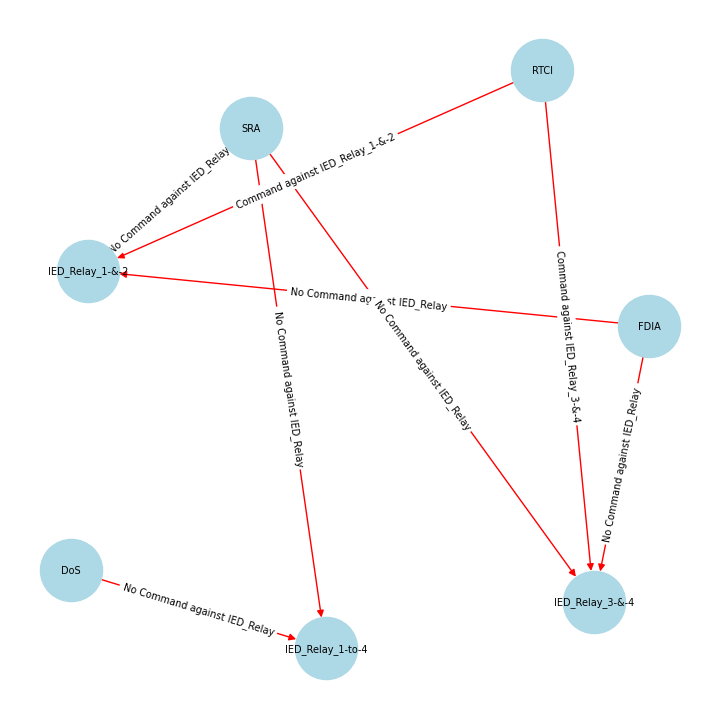

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Intelligent_electronic_device(IED)'].tolist()
relations = specific_triple_kg['Command_injection_against_IED_Relay'].tolist()
generate_kg(source, target, relations, 7, 7)


 Knowledge Graph generated


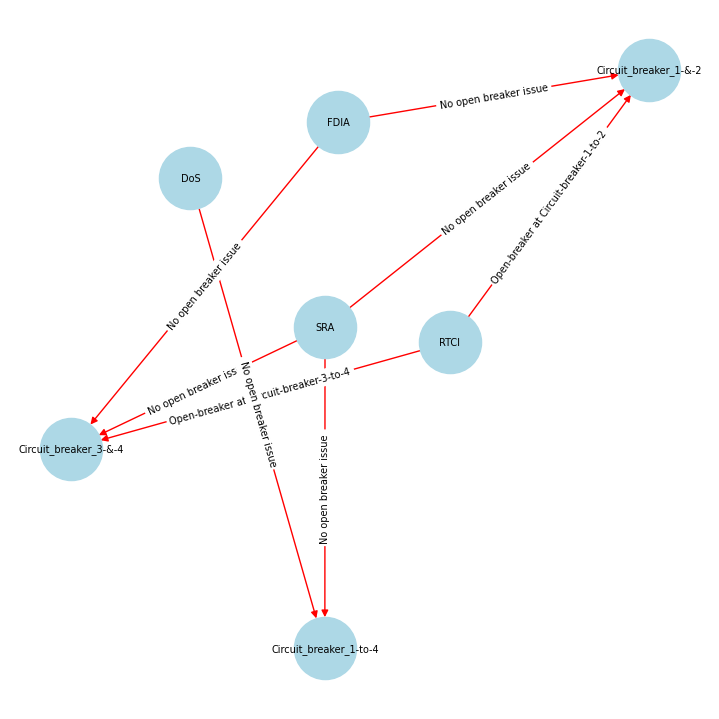

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Circuit_breaker_of_IED'].tolist()
relations = specific_triple_kg['Open_breaker_issue_by_command_injection'].tolist()
generate_kg(source, target, relations, 7, 7)


 Knowledge Graph generated


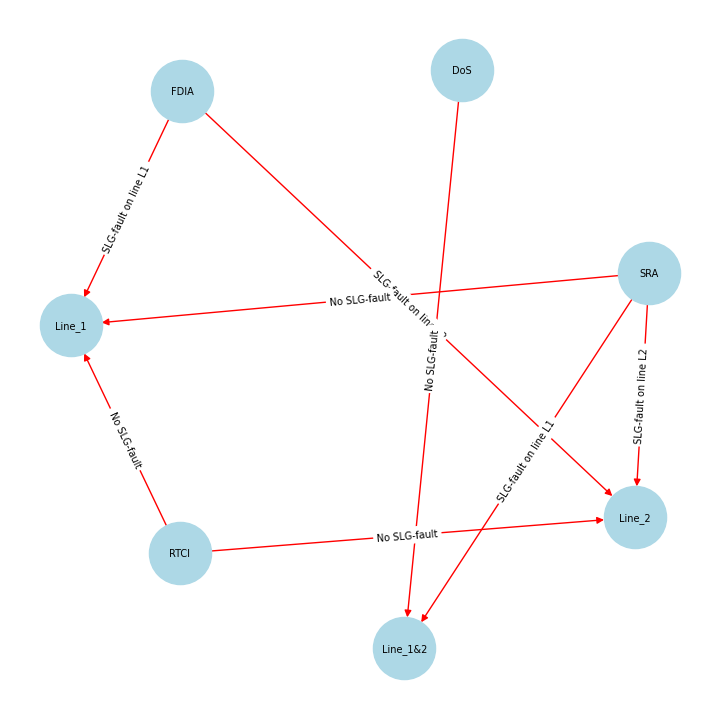

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Power_transmission_line_of_Circuit_breakers'].tolist()
relations = specific_triple_kg['Single-line-to-ground(SLG)_fault_of_power_line'].tolist()
generate_kg(source, target, relations, 7, 7)


 Knowledge Graph generated


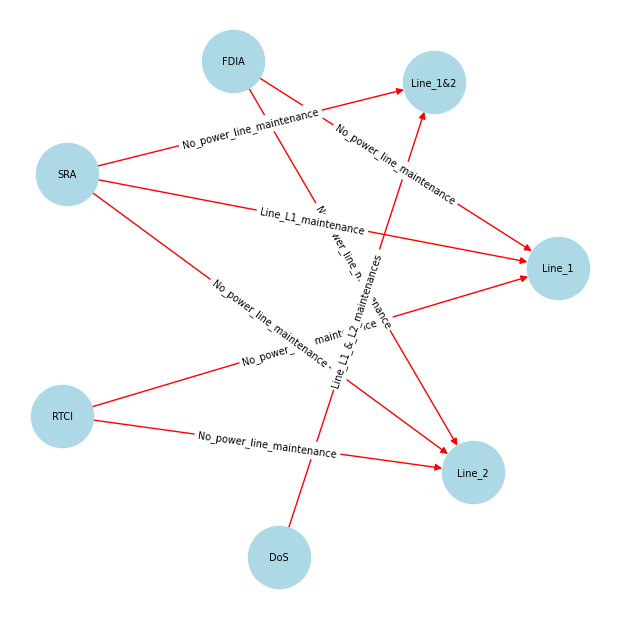

In [ ]:
source = specific_triple_kg['Cyber_attack'].tolist()
target = specific_triple_kg['Power_transmission_line_of_Circuit_breakers'].tolist()
relations = specific_triple_kg['Power_line_maintenance_issue'].tolist()
generate_kg(source, target, relations, 6, 6)

# **Shallow Machine Learning Process for Vulnerability Assesments**

**Label-encoding for FDIA, RTCI, DoS, SRA, Overall Cyber-attacks**

In [ ]:
OverallAttackData = data.drop('Scenario', axis=1)
CyberAttackData = OverallAttackData.drop('Vulnerable_event_type', axis=1)
OverallAttackData.rename(columns={'Cyber_attack': 'Cyber_attack_type', 'Vulnerable_event_type': 'Cyber_attack'}, inplace=True)

In [ ]:
def label_encoding(targetData, exclude_column, condition_value):
    # Initialize the label encoder
    label_encoder = LabelEncoder()

    # Ensure all columns are string type (important for comparison and encoding)
    dataLabelEncoding = targetData.applymap(str)

    # Process the target column (set to 1 if the value matches the condition, else 0)
    dataLabelEncoding[exclude_column] = dataLabelEncoding[exclude_column].apply(lambda x: 1 if x.strip() == condition_value else 0)

    # Encode other columns using label encoding
    for column in dataLabelEncoding.columns:
        if column != exclude_column:
            dataLabelEncoding[column] = label_encoder.fit_transform(dataLabelEncoding[column])

    return dataLabelEncoding

# Example Usage:
# Assuming 'CyberAttackData' is your dataframe with relevant data

LE_FDIAdata = label_encoding(CyberAttackData, 'Cyber_attack', 'FDIA')
LE_RTCIdata = label_encoding(CyberAttackData, 'Cyber_attack', 'RTCI')
LE_SRAdata = label_encoding(CyberAttackData, 'Cyber_attack', 'SRA')
LE_DoSdata = label_encoding(CyberAttackData, 'Cyber_attack', 'DoS')
LE_OverallCyberAttacksdata = label_encoding(OverallAttackData, 'Cyber_attack', 'Cyber_attack')


In [ ]:
#check
# LE_OverallCyberAttacksdata
LE_FDIAdata.head(10)
# LE_RTCIdata
# LE_SRAdata
# LE_DoSdata

,Cyber_attack,Intrusion,Network_device,Intelligent_electronic_device(IED),Circuit_breaker_of_IED,Power_transmission_line_of_Circuit_breakers,Single-line-to-ground(SLG)_fault_of_power_line,Tripping_command_issue_of_power_line,Command_injection_against_IED_Relay,IED_Relay_disabled_issue,IED_Relay_fault_issue,Open_breaker_issue_by_command_injection,Downtime_issue,Power_line_maintenance_issue
0,0,1,0,0,0,0,1,0,6,6,6,0,0,4
1,0,1,0,0,0,0,1,0,6,6,6,0,0,4
2,0,1,0,0,0,0,1,0,6,6,6,0,0,4
3,0,1,0,2,2,2,2,0,6,6,6,0,0,4
4,0,1,0,2,2,2,2,0,6,6,6,0,0,4
5,0,1,0,2,2,2,2,0,6,6,6,0,0,4
6,1,0,0,0,0,0,1,1,6,6,6,0,0,4
7,1,0,0,0,0,0,1,1,6,6,6,0,0,4
8,1,0,0,0,0,0,1,1,6,6,6,0,0,4
9,1,0,0,2,2,2,2,1,6,6,6,0,0,4


In [ ]:
def fit_voting_classifier(encodedData, cyberAttack_column, test_size=0.3, random_state=30):
    # Split data into features and labels
    X = encodedData.drop(cyberAttack_column, axis=1)
    y = encodedData[cyberAttack_column]

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)

    # Instantiate classifiers
    extra_trees = ExtraTreesClassifier(random_state=42)
    random_forest = RandomForestClassifier(random_state=42)
    bagging = BaggingClassifier(random_state=42)
    mlp = MLPClassifier(random_state=42)  # Shallow neural network (can adjust parameters)
    xgboost = xgb.XGBClassifier(random_state=42)

    # Create a VotingClassifier for ensemble
    voting_clf = VotingClassifier(
        estimators=[('extra_trees', extra_trees),
                    ('random_forest', random_forest),
                    ('bagging', bagging),
                    ('mlp', mlp),
                    ('xgboost', xgboost)],
        voting='soft'  # 'hard' for majority voting, 'soft' for probability-based voting
    )

    # Fit the ensemble model
    voting_clf.fit(X_train, y_train)

    # Make predictions
    y_pred = voting_clf.predict(X_test)

    return y_pred, voting_clf, X_train, X_test, y_train, y_test

In [ ]:
def severity_level(conf_matrix):
    # Mapping confusion matrix values to severity levels
    severity_map = {
        'TN': 1,  # Low Severity
        'FP': 2,  # Lower-Medium Severity
        'FN': 3,  # Medium Severity
        'TP': 4   # High Severity
    }

    # Extract TN, FP, FN, TP from the confusion matrix
    tn, fp, fn, tp = conf_matrix.ravel()

    # Calculate the weighted sum of severity levels
    weighted_sum = (tn * severity_map['TN'] +
                    fp * severity_map['FP'] +
                    fn * severity_map['FN'] +
                    tp * severity_map['TP'])

    # Calculate total number of elements in the confusion matrix
    total_elements = tn + fp + fn + tp

    # Calculate the weighted average severity
    avg_severity = weighted_sum / total_elements

    # Determine the overall severity level based on the new thresholds
    if avg_severity > 3 and avg_severity <= 4:
        return "High Severity"
    elif avg_severity > 2 and avg_severity <= 3:
        return "Medium Severity"
    elif avg_severity > 1 and avg_severity <= 2:
        return "Lower-Medium Severity"
    else:
        return "Low Severity"  # TN: 0 to 1

In [ ]:
def evaluate_model(y_test, y_pred, voting_clf, X_test):
    """
    Evaluate the model performance using various metrics and plots.

    Parameters:
    - y_test: True labels for the test set.
    - y_pred: Predicted labels from the model.
    - voting_clf: The trained VotingClassifier model.
    - X_test: Features of the test set used to generate predictions for AUC and Log Loss.

    Prints and plots evaluation metrics including accuracy, confusion matrix, classification report, etc.
    """
    # Calculate Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.4f}")

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(conf_matrix)

    # Overall severity
    severity = severity_level(conf_matrix)
    print(f"severity level: {severity}")

    # Classification Report
    class_report = classification_report(y_test, y_pred)
    print("Classification Report:")
    print(class_report)

    # Precision, Recall, F1-Score (weighted average)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

    # ROC AUC (For binary classification)
    roc_auc = roc_auc_score(y_test, voting_clf.predict_proba(X_test)[:, 1])
    print(f"ROC AUC: {roc_auc:.4f}")

    # Log Loss (if using soft voting)
    logloss = log_loss(y_test, voting_clf.predict_proba(X_test))
    print(f"Log Loss: {logloss:.4f}")

    # ROC Curve (for binary classification)
    fpr, tpr, _ = roc_curve(y_test, voting_clf.predict_proba(X_test)[:, 1])
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', label='ROC Curve')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='best')
    plt.show()

    # Return the metrics
    return conf_matrix, accuracy, precision, recall, f1, roc_auc, logloss, severity

In [ ]:
def plot_confusion_matrix_with_severity(conf_matrix, severity, attack_label, non_attack_label):
    """
    Calculates the confusion matrix, prints the individual counts (TN, FP, FN, TP),
    and plots the confusion matrix with severity labels.

    Parameters:
    - y_test: True labels for the test set.
    - y_pred: Predicted labels from the model.
    - severity: The severity level label to display in the plot title (default is 'High').

    Returns:
    - tn, fp, fn, tp: True Negatives, False Positives, False Negatives, True Positives from the confusion matrix.
    """
    # get confusion matrix
    cm = conf_matrix

    # Get TN, FP, FN, TP values
    tn, fp, fn, tp = cm.ravel()

    # Print confusion matrix and severity label
    print("Confusion Matrix:")
    print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

    # Custom annotations for each cell in the matrix
    annotations = np.array([
        [f'True-Negative (TN):\n {tn}\n\nLow-Severity', f'False-Positive (FP):\n {fp}\n\nLower-Medium-Severity'],
        [f'False-Negative (FN):\n {fn}\n\nMedium-Severity', f'True-Positive (TP):\n {tp}\n\nHigh-Severity']
    ])

    # Plot confusion matrix with severity label
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=annotations, fmt='', cmap="Reds", xticklabels=[f"{non_attack_label} (0)", f"{attack_label} (1)"],
                yticklabels=[f"{non_attack_label} (0)", f"{attack_label} (1)"])
    plt.title(f"Severity Level: {severity}", fontsize=14)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

    # Return the confusion matrix values
    return tn, fp, fn, tp, annotations

In [ ]:
# List of cyber attack column names
cyber_attack_columns = ['FDIA', 'RTCI', 'SRA', 'DoS', 'CyberAttack']

# Dictionary mapping attack columns to their respective DataFrames
cyber_attack_datasets = {
    'FDIA': LE_FDIAdata,
    'RTCI': LE_RTCIdata,
    'SRA': LE_SRAdata,
    'DoS': LE_DoSdata,
    'CyberAttack': LE_OverallCyberAttacksdata
}

# Initialize dictionaries to store overall metrics for all attack columns
overall_metrics = {
    'accuracy': [],
    'precision': [],
    'recall': [],
    'f1': [],
    'roc_auc': [],
    'logloss': []
}

# Initialize a dictionary to store confusion matrices for all cyber attacks
confusion_matrices = {}


## Evaluating FDIA... 
Accuracy: 1.0000
Confusion Matrix:
[[137   0]
 [  0  14]]
severity level: Lower-Medium Severity
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       137
           1       1.00      1.00      1.00        14

    accuracy                           1.00       151
   macro avg       1.00      1.00      1.00       151
weighted avg       1.00      1.00      1.00       151

Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Log Loss: 0.0033


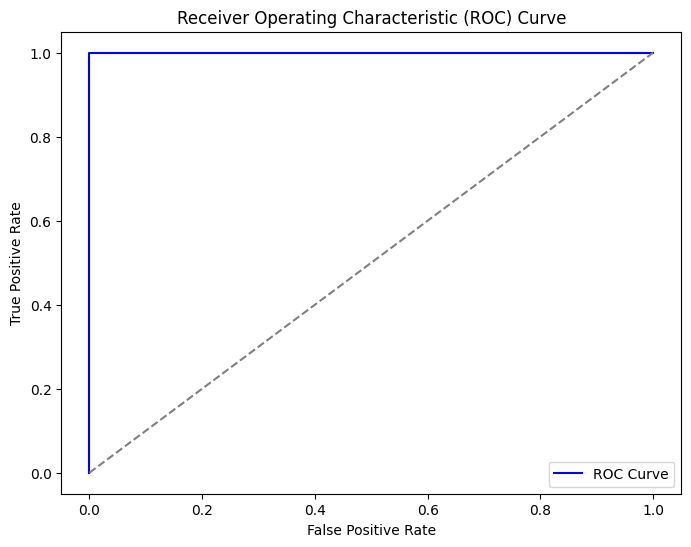

Confusion Matrix:
TN: 137, FP: 0, FN: 0, TP: 14


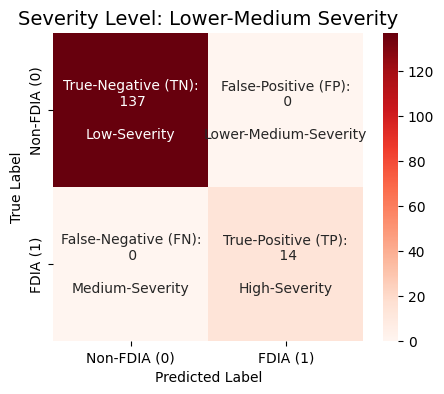

True-Negative (TN):  137  Low-Severity; False-Positive (FP):  0  Lower-Medium-Severity; False-Negative (FN):  0  Medium-Severity; True-Positive (TP):  14  High-Severity



## Evaluating RTCI... 
Accuracy: 1.0000
Confusion Matrix:
[[132   0]
 [  0  19]]
severity level: Lower-Medium Severity
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       132
           1       1.00      1.00      1.00        19

    accuracy                           1.00       151
   macro avg       1.00      1.00      1.00       151
weighted avg       1.00      1.00      1.00       151

Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Log Loss: 0.0016


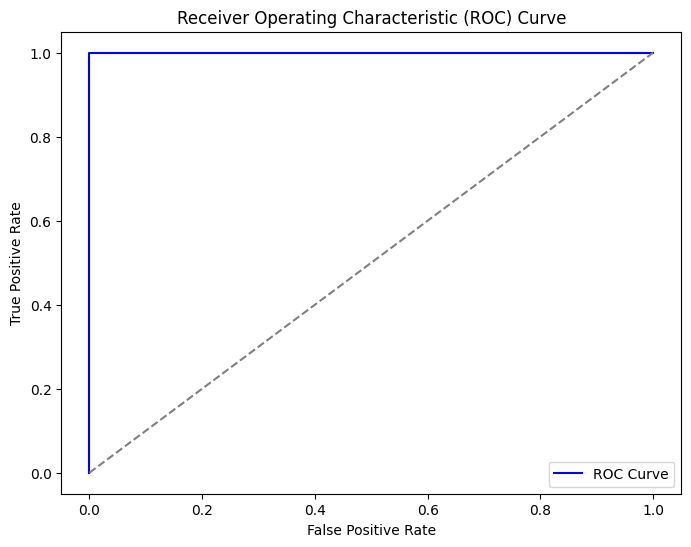

Confusion Matrix:
TN: 132, FP: 0, FN: 0, TP: 19


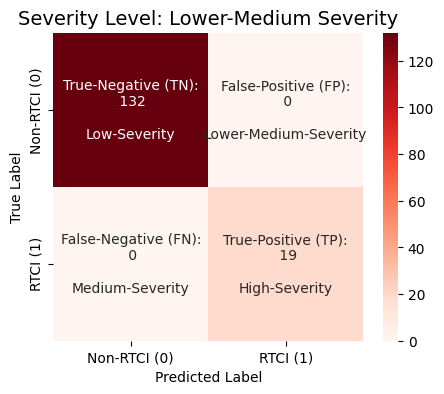

True-Negative (TN):  132  Low-Severity; False-Positive (FP):  0  Lower-Medium-Severity; False-Negative (FN):  0  Medium-Severity; True-Positive (TP):  19  High-Severity



## Evaluating SRA... 
Accuracy: 1.0000
Confusion Matrix:
[[87  0]
 [ 0 64]]
severity level: Medium Severity
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        87
           1       1.00      1.00      1.00        64

    accuracy                           1.00       151
   macro avg       1.00      1.00      1.00       151
weighted avg       1.00      1.00      1.00       151

Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Log Loss: 0.0020


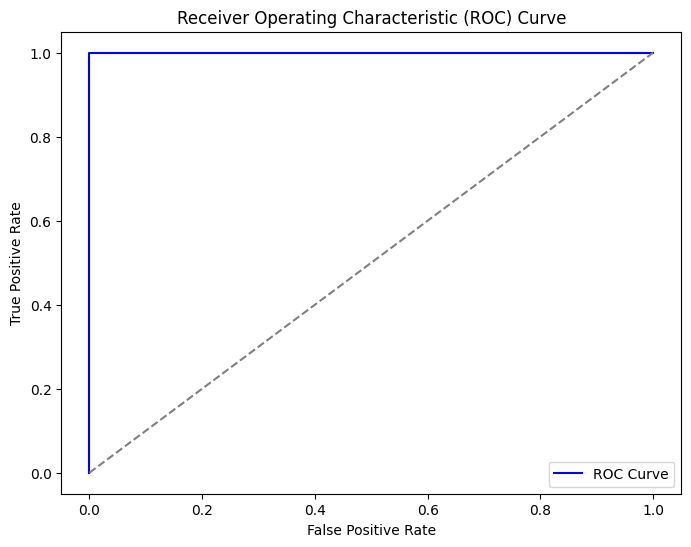

Confusion Matrix:
TN: 87, FP: 0, FN: 0, TP: 64


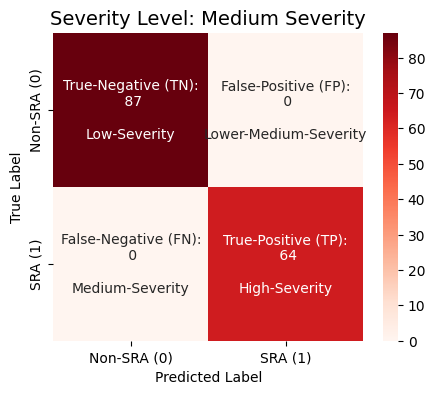

True-Negative (TN):  87  Low-Severity; False-Positive (FP):  0  Lower-Medium-Severity; False-Negative (FN):  0  Medium-Severity; True-Positive (TP):  64  High-Severity



## Evaluating DoS... 
Accuracy: 1.0000
Confusion Matrix:
[[137   0]
 [  0  14]]
severity level: Lower-Medium Severity
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       137
           1       1.00      1.00      1.00        14

    accuracy                           1.00       151
   macro avg       1.00      1.00      1.00       151
weighted avg       1.00      1.00      1.00       151

Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Log Loss: 0.0027


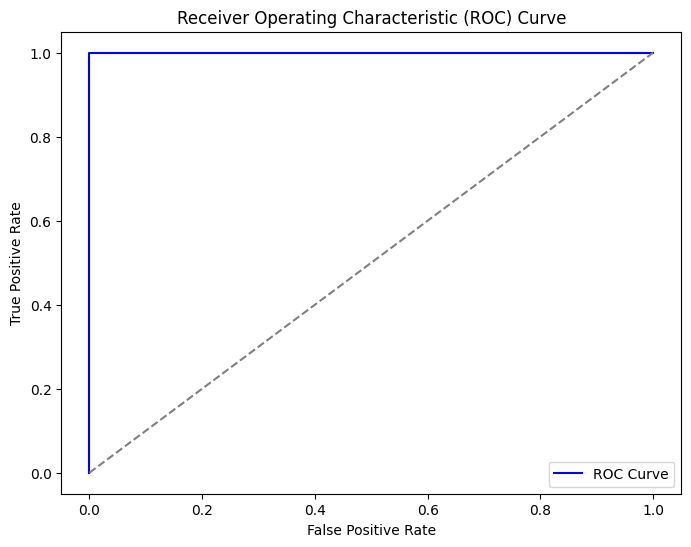

Confusion Matrix:
TN: 137, FP: 0, FN: 0, TP: 14


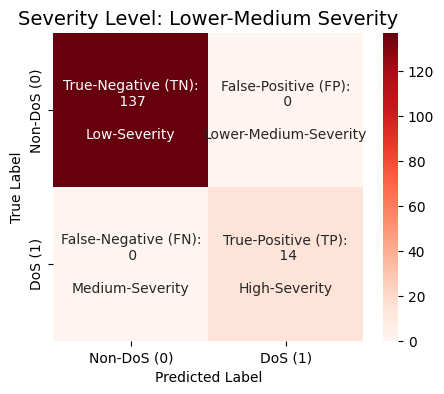

True-Negative (TN):  137  Low-Severity; False-Positive (FP):  0  Lower-Medium-Severity; False-Negative (FN):  0  Medium-Severity; True-Positive (TP):  14  High-Severity



## Evaluating CyberAttack... 
Accuracy: 1.0000
Confusion Matrix:
[[ 40   0]
 [  0 111]]
severity level: High Severity
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00       111

    accuracy                           1.00       151
   macro avg       1.00      1.00      1.00       151
weighted avg       1.00      1.00      1.00       151

Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000
Log Loss: 0.0027


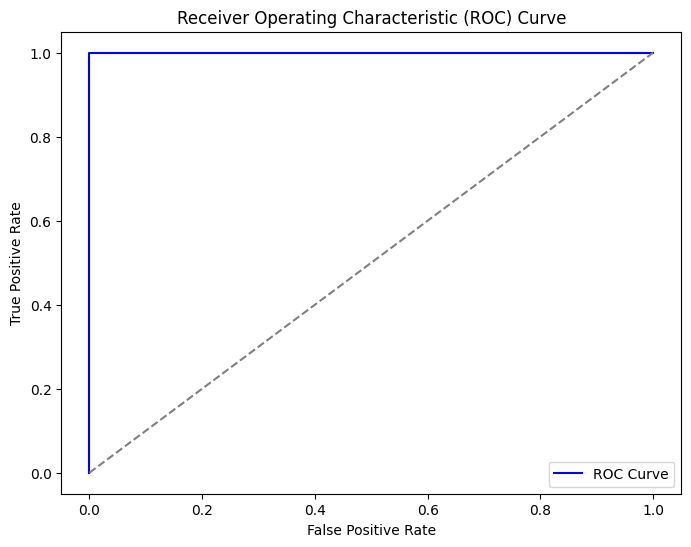

Confusion Matrix:
TN: 40, FP: 0, FN: 0, TP: 111


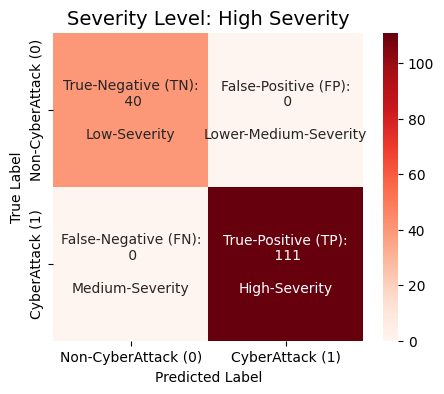

True-Negative (TN):  40  Low-Severity; False-Positive (FP):  0  Lower-Medium-Severity; False-Negative (FN):  0  Medium-Severity; True-Positive (TP):  111  High-Severity




In [ ]:
# ANSI Escape code for bold text
BOLD = '\033[1m'
RESET = '\033[0m'

# Loop through each cyber-attack column
for attack_column in cyber_attack_columns:
    print(f"\n{BOLD}## Evaluating {attack_column}... {RESET}")

    attack_data = cyber_attack_datasets[attack_column]

    # Fit the voting classifier model
    y_pred, voting_clf, X_train, X_test, y_train, y_test = fit_voting_classifier(attack_data, cyberAttack_column='Cyber_attack')

    # Evaluate the model and get metrics
    conf_matrix, accuracy, precision, recall, f1, roc_auc, logloss, severity = evaluate_model(y_test, y_pred, voting_clf, X_test)

    # Dynamically create attack and non-attack labels
    attack_label = attack_column
    non_attack_label = f"Non-{attack_column}"

    tn, fp, fn, tp, annotations = plot_confusion_matrix_with_severity(conf_matrix, severity, attack_label, non_attack_label)
    annotations_str = '; '.join([annotation.replace('\n', ' ') for annotation in annotations.flatten()])
    print(annotations_str)

    # Add the metrics to the overall lists
    overall_metrics['accuracy'].append(accuracy)
    overall_metrics['precision'].append(precision)
    overall_metrics['recall'].append(recall)
    overall_metrics['f1'].append(f1)
    overall_metrics['roc_auc'].append(roc_auc)
    overall_metrics['logloss'].append(logloss)
    confusion_matrices[attack_column] = conf_matrix

    print("\n")


In [ ]:
# Overall Model Scores

# Calculate overall metrics first with 'SL (Shellow LEarning)' prefix
SL_accuracy = sum(overall_metrics['accuracy']) / len(overall_metrics['accuracy'])
SL_precision = sum(overall_metrics['precision']) / len(overall_metrics['precision'])
SL_recall = sum(overall_metrics['recall']) / len(overall_metrics['recall'])
SL_f1_score = sum(overall_metrics['f1']) / len(overall_metrics['f1'])
SL_roc_auc = sum(overall_metrics['roc_auc']) / len(overall_metrics['roc_auc'])
SL_log_loss = sum(overall_metrics['logloss']) / len(overall_metrics['logloss'])

# Print the results with 'SL_' prefix
print(f"{BOLD}## Overall Metrics Across All Cyber Attacks{RESET}")
print(f"Accuracy: {SL_accuracy:.3f}")
print(f"Precision: {SL_precision:.3f}")
print(f"Recall: {SL_recall:.3f}")
print(f"F1-Score: {SL_f1_score:.3f}")
print(f"ROC-AUC: {SL_roc_auc:.3f}")
print(f"Log Loss: {SL_log_loss:.3f}")

for attack_column, cm in confusion_matrices.items():
    print(f"Confusion Matrix for {attack_column}:")
    print(cm)
    print("\n")

## Overall Metrics Across All Cyber Attacks
Accuracy: 1.000
Precision: 1.000
Recall: 1.000
F1-Score: 1.000
ROC-AUC: 1.000
Log Loss: 0.002
Confusion Matrix for FDIA:
[[137   0]
 [  0  14]]


Confusion Matrix for RTCI:
[[132   0]
 [  0  19]]


Confusion Matrix for SRA:
[[87  0]
 [ 0 64]]


Confusion Matrix for DoS:
[[137   0]
 [  0  14]]


Confusion Matrix for CyberAttack:
[[ 40   0]
 [  0 111]]


